# MNIST con redes recurrentes

# Ejemplo a : MNIST con RNN Simple

## Cargar el conjunto de datos MNIST

In [ ]:
# Importa el dataset MNIST (imágenes de dígitos del 0 al 9)
mnist = mnist
mnist

<module 'keras.datasets.mnist' from '/usr/local/lib/python3.12/dist-packages/keras/datasets/mnist/__init__.py'>

In [ ]:
# Carga los datos de entrenamiento y prueba: imágenes y etiquetas
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train.shape, x_test.shape

((60000, 28, 28), (10000, 28, 28))

## Preprocesamiento de los datos

In [ ]:
# Normaliza los píxeles de las imágenes dividiendo entre 255 para que estén en el rango [0, 1]
x_train, x_test = x_train / 255.0, x_test / 255.0

## RNN

### Construcción del modelo

In [ ]:
# Crea un modelo secuencial con capas apiladas
model = Sequential([

    # Capa RNN simple con 50 unidades
    # input_shape=(28,28) indica 28 pasos de tiempo con 28 características cada uno (una fila de la imagen)
    SimpleRNN(50, input_shape=(28, 28)),

    # Capa densa de salida con 10 unidades y activación softmax para clasificar los dígitos del 0 al 9
    Dense(10, activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
# Compila el modelo RNN con configuraciones de entrenamiento
model.compile(
    # Optimizer Adam para actualización eficiente de pesos
    optimizer='adam',

    # Función de pérdida para clasificación de enteros (0-9)
    loss='sparse_categorical_crossentropy',

    # Métrica para monitorear durante el entrenamiento
    metrics=['accuracy']
)

In [ ]:
model(x_train)

<tf.Tensor: shape=(60000, 10), dtype=float32, numpy=
array([[0.11622211, 0.07003267, 0.12269932, ..., 0.12297745, 0.0928225 ,
        0.0992564 ],
       [0.11334807, 0.06710673, 0.12583925, ..., 0.108859  , 0.10292087,
        0.13090083],
       [0.12002575, 0.10172072, 0.13332243, ..., 0.06894451, 0.10027655,
        0.08483332],
       ...,
       [0.08285129, 0.04621783, 0.15791981, ..., 0.05703712, 0.1564929 ,
        0.08467443],
       [0.10401167, 0.10676317, 0.10363085, ..., 0.09334286, 0.08875256,
        0.12373588],
       [0.10037965, 0.06649832, 0.13160795, ..., 0.08432183, 0.13784122,
        0.08029507]], dtype=float32)>

La red recibe un vector de 28 valores (píxeles) en cada celda recurrente (paso de tiempo), no un solo valor

In [ ]:
# Muestra un resumen de la arquitectura del modelo, incluyendo capas, parámetros y forma de salida
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 50)             │         3,950 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,460 (17.42 KB)

 Trainable params: 4,460 (17.42 KB)

 Non-trainable params: 0 (0.00 B)

Cada paso de tiempo en una RNN procesa un único elemento de la secuencia y cuando usamos una RNN para MNIST, definimos la secuencia de la siguiente manera:

1. La Secuencia (Pasos de Tiempo $T$): La longitud de la secuencia es 28 (el número de filas).
2. El Elemento de la Secuencia ($I$): El elemento de la secuencia en cada paso de tiempo es un vector completo de 28 píxeles (la fila).

La capa SimpleRNN toma el vector de 28 píxeles, lo combina con su estado de memoria anterior y produce un nuevo estado de memoria, repitiendo este proceso 28 veces.

**Secuencialización de Imagen MNIST para RNN (28x28)**

| Paso de Tiempo ($t$) | Elemento Procesado | Dimensión del Elemento ($I$) |
| :---: | :--- | :---: |
| **$t=1$** | Fila 1 (28 píxeles) | 28 |
| **$t=2$** | Fila 2 (28 píxeles) | 28 |
| $\dots$ | $\dots$ | $\dots$ |
| **$t=28$** | Fila 28 (28 píxeles) | 28 |

### Entrenamiento del modelo

In [ ]:
# Entrena el modelo RNN con los datos de entrenamiento durante 5 épocas
# Usa el conjunto de prueba para validar el rendimiento en cada época
history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.8051 - loss: 0.6306 - val_accuracy: 0.9017 - val_loss: 0.3465
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9073 - loss: 0.3196 - val_accuracy: 0.9183 - val_loss: 0.2783
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9258 - loss: 0.2565 - val_accuracy: 0.9269 - val_loss: 0.2471
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9374 - loss: 0.2205 - val_accuracy: 0.9406 - val_loss: 0.2078
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9410 - loss: 0.2071 - val_accuracy: 0.9415 - val_loss: 0.2092


### Evaluación del modelo

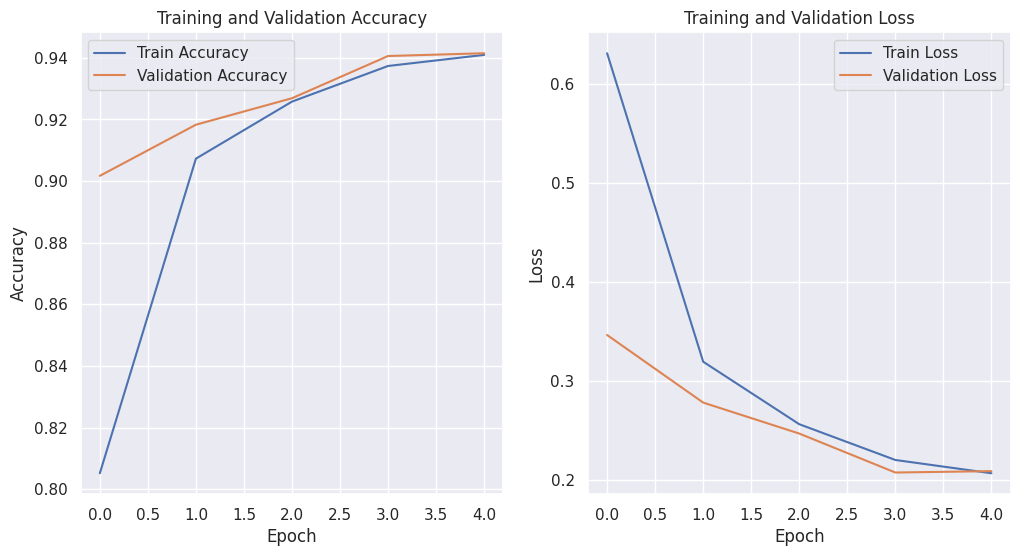

In [ ]:
# Configura estilo de Seaborn para los gráficos
sns.set()

# Crea una figura de tamaño 12x6 pulgadas
plt.figure(figsize=(12, 6))

# Primer subplot: precisión de entrenamiento y validación
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')       # Precisión en el entrenamiento
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')  # Precisión en validación
plt.title('Training and Validation Accuracy')                       # Título del gráfico
plt.xlabel('Epoch')                                                  # Etiqueta eje X
plt.ylabel('Accuracy')                                               # Etiqueta eje Y
plt.legend()                                                         # Muestra leyenda

# Segundo subplot: pérdida de entrenamiento y validación
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')               # Pérdida en entrenamiento
plt.plot(history.history['val_loss'], label='Validation Loss')      # Pérdida en validación
plt.title('Training and Validation Loss')                            # Título del gráfico
plt.xlabel('Epoch')                                                  # Etiqueta eje X
plt.ylabel('Loss')                                                   # Etiqueta eje Y
plt.legend()                                                         # Muestra leyenda

# Muestra ambos gráficos en pantalla
plt.show()

---

# Ejemplo b: MNIST con LSTM

### Construcción del modelo

In [ ]:
# Crea un modelo secuencial con capas apiladas
model_lstm = Sequential([

    # Capa LSTM con 50 unidades
    # input_shape=(28,28) indica 28 pasos de tiempo con 28 características cada uno (una fila de la imagen)
    LSTM(50, input_shape=(28, 28)),

    # Capa densa de salida con 10 unidades y activación softmax para clasificar los dígitos del 0 al 9
    Dense(10, activation='softmax')
])

In [ ]:
# Compila el modelo LSTM con configuraciones de entrenamiento
model_lstm.compile(
    # Optimizer Adam para actualización eficiente de pesos
    optimizer='adam',

    # Función de pérdida para clasificación de enteros (0-9)
    loss='sparse_categorical_crossentropy',

    # Métrica para monitorear durante el entrenamiento
    metrics=['accuracy']
)

In [ ]:
# Muestra un resumen de la arquitectura del modelo LSTM, incluyendo capas, parámetros y forma de salida
model_lstm.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        15,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,310 (63.71 KB)

 Trainable params: 16,310 (63.71 KB)

 Non-trainable params: 0 (0.00 B)

### Entrenamiento del modelo

In [ ]:
# Entrenar el modelo LSTM
history_lstm = model_lstm.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.8567 - loss: 0.4581 - val_accuracy: 0.9527 - val_loss: 0.1576
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9553 - loss: 0.1486 - val_accuracy: 0.9661 - val_loss: 0.1139
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9682 - loss: 0.1093 - val_accuracy: 0.9694 - val_loss: 0.1008
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9728 - loss: 0.0905 - val_accuracy: 0.9745 - val_loss: 0.0838
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.9781 - loss: 0.0745 - val_accuracy: 0.9671 - val_loss: 0.1078


### Evaluacion del modelo

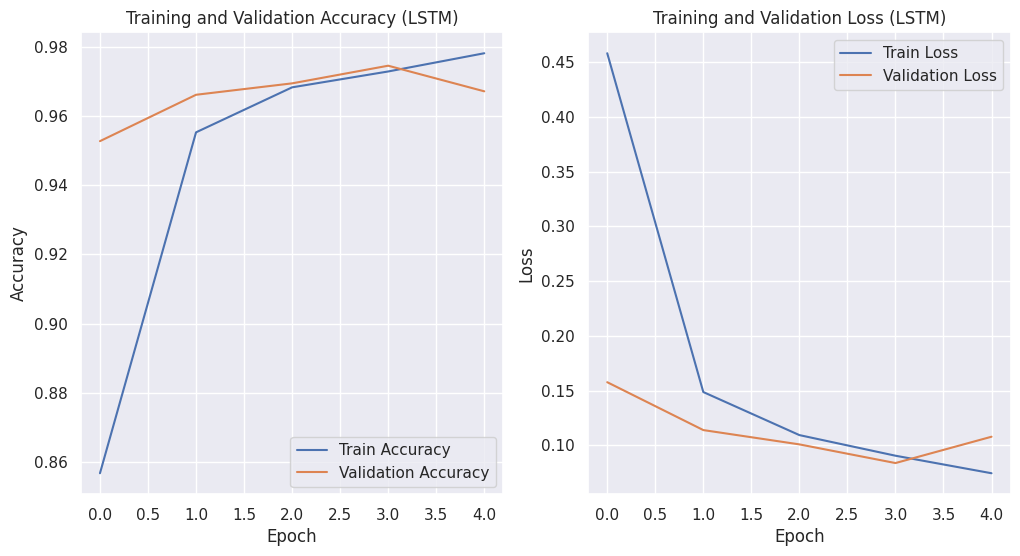

In [ ]:
# Crea una figura de tamaño 12x6 pulgadas
plt.figure(figsize=(12, 6))

# Primer subplot: precisión de entrenamiento y validación para LSTM
plt.subplot(1, 2, 1)
plt.plot(history_lstm.history['accuracy'], label='Train Accuracy')       # Precisión en entrenamiento
plt.plot(history_lstm.history['val_accuracy'], label='Validation Accuracy')  # Precisión en validación
plt.title('Training and Validation Accuracy (LSTM)')                     # Título del gráfico
plt.xlabel('Epoch')                                                      # Etiqueta eje X
plt.ylabel('Accuracy')                                                   # Etiqueta eje Y
plt.legend()                                                             # Muestra leyenda

# Segundo subplot: pérdida de entrenamiento y validación para LSTM
plt.subplot(1, 2, 2)
plt.plot(history_lstm.history['loss'], label='Train Loss')               # Pérdida en entrenamiento
plt.plot(history_lstm.history['val_loss'], label='Validation Loss')      # Pérdida en validación
plt.title('Training and Validation Loss (LSTM)')                          # Título del gráfico
plt.xlabel('Epoch')                                                      # Etiqueta eje X
plt.ylabel('Loss')                                                       # Etiqueta eje Y
plt.legend()                                                             # Muestra leyenda

# Muestra ambos gráficos en pantalla
plt.show()